# DSCI 552 — Homework 6

Name: Zhicheng Zhang  
GitHub Username: Hustzz-Max  
USC ID: 8006795737

## 1. Tree-Based Methods

### 1(a–b). Data and median imputation

I used the supplied training and test files from [UCI](https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks). Common ways to fill missing values include the mean, the median, nearest neighbors, and prediction from other columns. I chose the median because extreme values have less effect on it. Following the assignment footnote, I used each split's own column medians, without using its labels.

In [1]:
from pathlib import Path
from math import isqrt

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from IPython.display import display
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

plt.rcParams.update({'figure.dpi': 145, 'axes.spines.top': False,
                     'axes.spines.right': False})
seed = 42
data_dir = Path('../data')
if not data_dir.is_dir():
    data_dir = Path('data') if Path('data').is_dir() else Path('HW6/data')

def load_aps(split):
    data = pd.read_csv(data_dir / f'aps_failure_{split}_set.csv',
                       skiprows=20, na_values='na')
    labels = data.pop('class').map({'neg': 0, 'pos': 1}).to_numpy()
    return data.astype('float32'), labels

def fill_medians(features):
    imputer = SimpleImputer(strategy='median', keep_empty_features=True)
    return imputer.fit_transform(features)

raw_train, y_train = load_aps('training')
raw_test, y_test = load_aps('test')
X_train = fill_medians(raw_train)
X_test = fill_medians(raw_test)
train = pd.DataFrame(X_train, columns=raw_train.columns)

counts = pd.DataFrame([np.bincount(y_train), np.bincount(y_test)],
                      index=['Train', 'Test'], columns=['Negative', 'Positive'])
counts['Positive %'] = (100 * counts['Positive'] / counts.sum(axis=1)).round(2)
display(counts)
print(f'{train.shape[1]} features; missing training entries: '
      f'{raw_train.isna().to_numpy().sum():,}')

,Negative,Positive,Positive %
Train,59000,1000,1.67
Test,15625,375,2.34


170 features; missing training entries: 850,015


The training set is highly imbalanced: only 1.67% of the rows are positive.

### 1(b)(ii). Coefficients of variation

I divided each feature's sample standard deviation by its mean. A zero mean makes the coefficient undefined.

In [2]:
means = train.mean()
cv = (train.std(ddof=1) / means.replace(0, np.nan)).rename('CV')
cv_table = cv.sort_values(ascending=False).rename_axis('Feature').reset_index()
cv_blocks = [cv_table.iloc[rows].reset_index(drop=True)
             for rows in np.array_split(np.arange(len(cv_table)), 5)]
cv_wide = pd.concat(cv_blocks, axis=1, keys=range(1, 6))
display(cv_wide.style.format(precision=3, na_rep='Undefined')
        .hide(axis='index').hide(axis='columns', level=0))

Feature,CV,Feature,CV,Feature,CV,Feature,CV,Feature,CV
cf_000,244.888,ay_003,28.735,be_000,6.847,cs_003,3.132,bb_000,2.405
co_000,244.507,cn_000,26.336,ba_008,6.831,ap_000,3.081,bv_000,2.405
ad_000,244.323,ae_000,24.200,cn_002,6.707,dd_000,3.057,cq_000,2.405
cs_009,237.931,at_000,23.708,cu_000,6.673,ck_000,3.056,bu_000,2.405
dh_000,123.216,az_008,22.680,cn_007,6.335,ay_006,3.053,ci_000,2.400
dj_000,117.494,dq_000,22.030,bz_000,6.314,az_005,3.035,ed_000,2.394
ag_000,92.918,af_000,19.471,db_000,6.259,ba_006,3.031,ag_006,2.357
as_000,87.333,ai_000,18.204,ag_008,6.221,bi_000,3.022,cn_005,2.345
ay_009,84.734,ag_002,17.566,av_000,6.006,ag_005,2.956,ds_000,2.320
ak_000,80.425,az_007,16.229,ee_009,5.692,du_000,2.918,ah_000,2.312


### 1(b)(iii). Correlation matrix

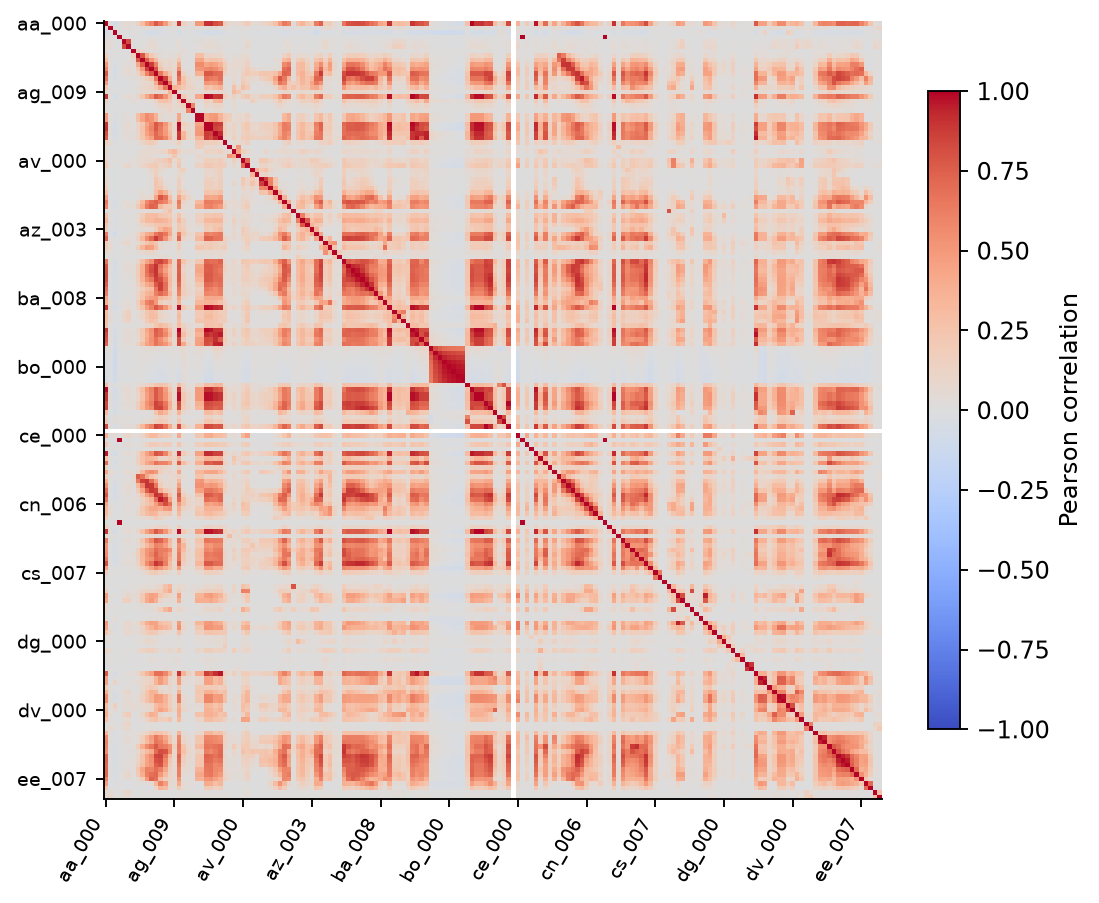

In [3]:
corr = train.corr()
fig, ax = plt.subplots(figsize=(6.7, 5.2), layout='constrained')
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1, interpolation='nearest')
ticks = np.arange(0, len(corr), 15)
ax.set_xticks(ticks, corr.columns[ticks], rotation=60, ha='right', fontsize=8)
ax.set_yticks(ticks, corr.index[ticks], fontsize=8)
fig.colorbar(image, ax=ax, label='Pearson correlation', shrink=0.82)
plt.show()

### 1(b)(iv). Scatterplots and boxplots

I used the 13 highest-CV features for plotting. The axes use a signed log transform to make small values visible. The scatterplots show every positive and a random sample of 1,000 negatives. The boxplots use all training rows and hide individual outlier points.

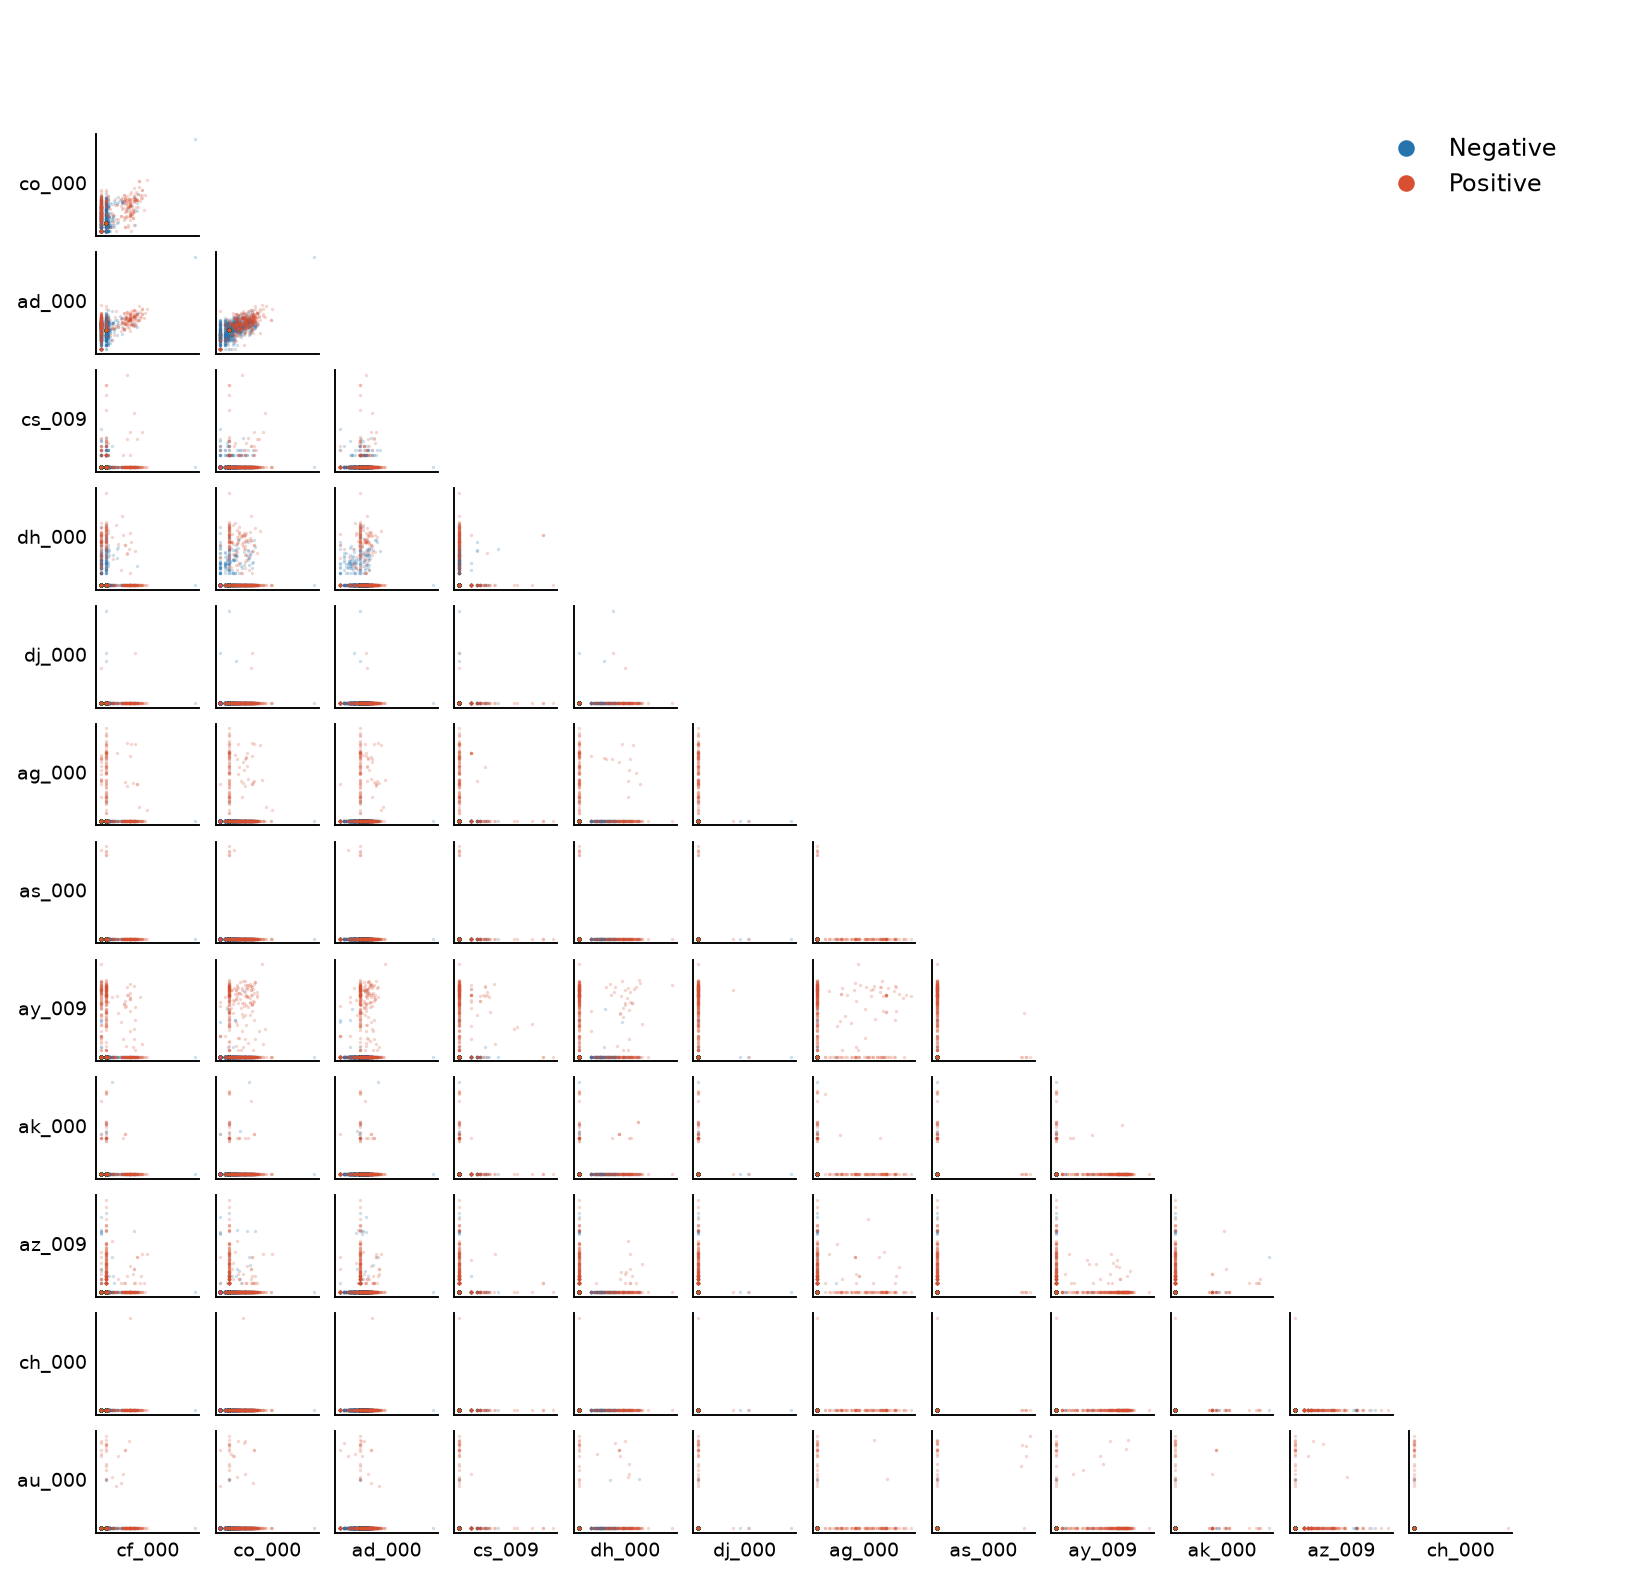

In [4]:
top = cv.nlargest(isqrt(train.shape[1])).index.tolist()
values = train[top].to_numpy()
plot_values = np.sign(values) * np.log1p(np.abs(values))
colors = ['#2673ad', '#d85031']
rng = np.random.default_rng(seed)
negative_rows = rng.choice(np.flatnonzero(y_train == 0), size=1000, replace=False)
positive_rows = np.flatnonzero(y_train == 1)
size = len(top)
fig, axes = plt.subplots(size, size, figsize=(10.5, 9.8))
for row in range(size):
    for col in range(size):
        ax = axes[row, col]
        if row <= col:
            ax.set_axis_off()
            continue
        for rows, color in zip((negative_rows, positive_rows), colors):
            ax.scatter(plot_values[rows, col], plot_values[rows, row],
                       s=2, alpha=0.23, color=color, linewidths=0)
        ax.set(xticks=[], yticks=[])
        if row == size - 1:
            ax.set_xlabel(top[col], fontsize=8)
        if col == 0:
            ax.set_ylabel(top[row], fontsize=8, rotation=0, ha='right', va='center')

handles = [Line2D([], [], marker='o', linestyle='', color=color, label=label)
           for color, label in zip(colors, ('Negative', 'Positive'))]
fig.legend(handles=handles, loc='upper right', bbox_to_anchor=(0.95, 0.92), frameon=False)
fig.subplots_adjust(left=0.12, bottom=0.07, right=0.98, top=0.98, wspace=0.16, hspace=0.16)
plt.show()

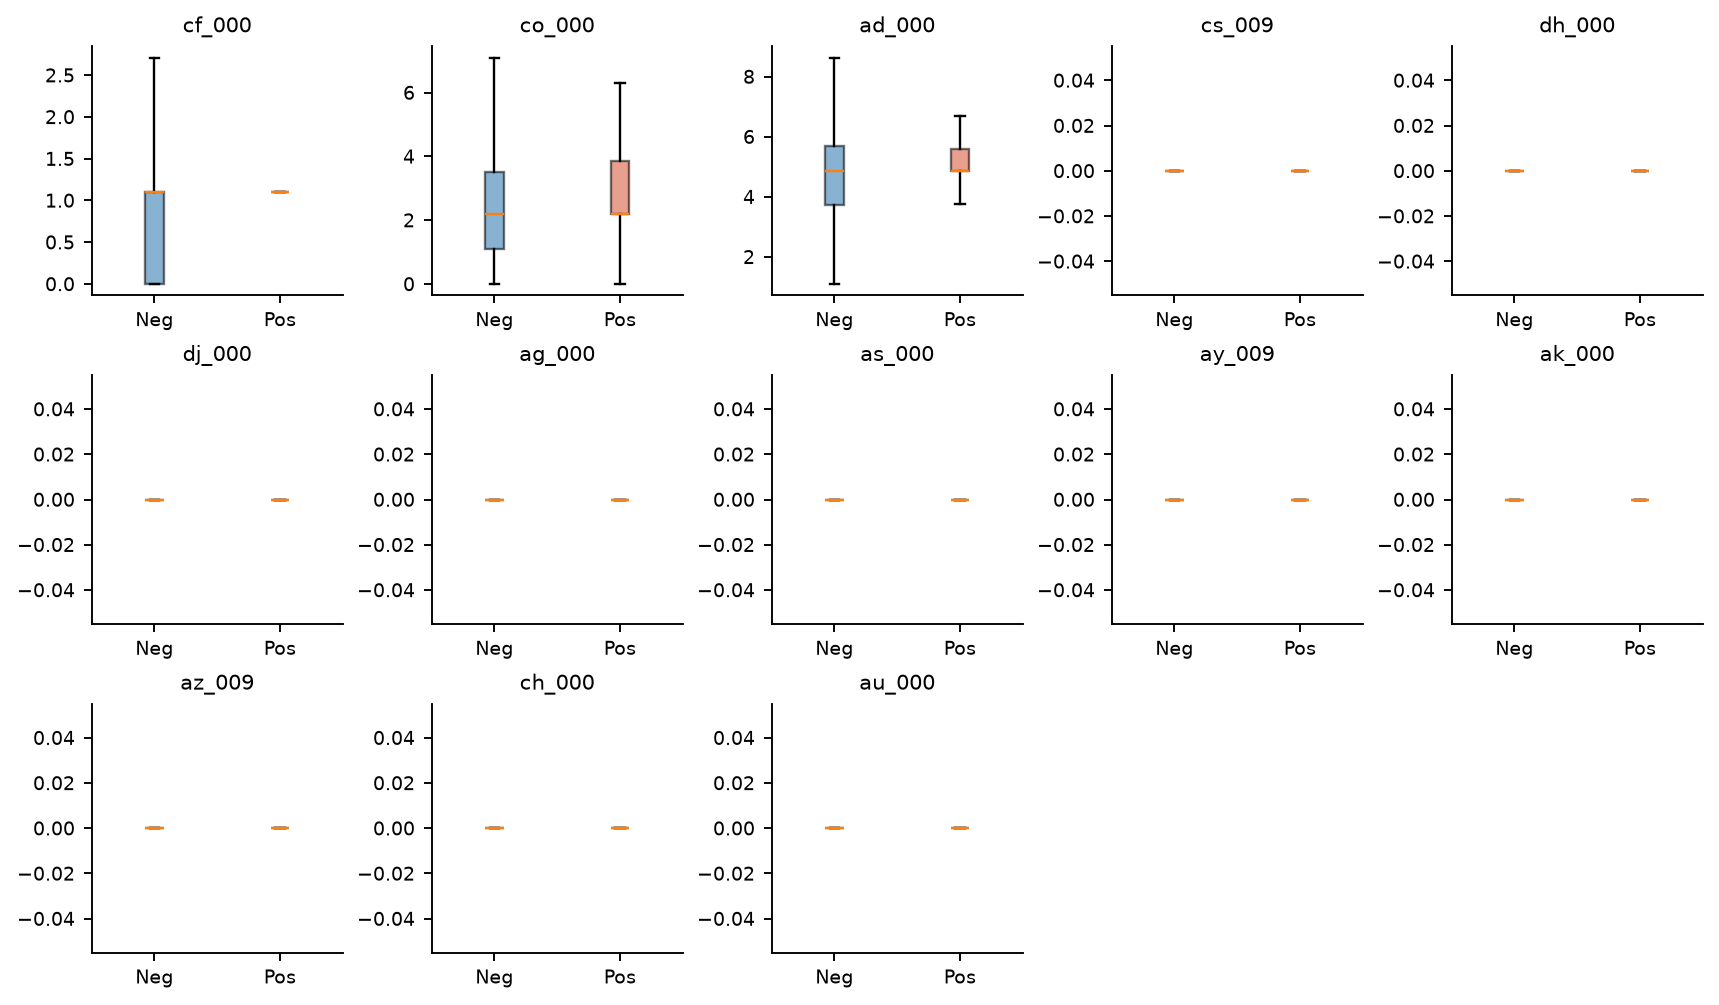

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(10, 5.8), layout='constrained')
for col, (name, ax) in enumerate(zip(top, axes.flat)):
    groups = [plot_values[y_train == label, col] for label in (0, 1)]
    boxes = ax.boxplot(groups, tick_labels=['Neg', 'Pos'],
                       showfliers=False, patch_artist=True)
    for box, color in zip(boxes['boxes'], colors):
        box.set_facecolor(color)
        box.set_alpha(0.55)
    ax.set_title(name, fontsize=9)
    ax.tick_params(labelsize=8)

for ax in axes.flat[len(top):]:
    ax.set_axis_off()
plt.show()

Some plots suggest class differences, but there is still overlap. A high CV measures spread relative to the mean. I would need more evidence to tell whether a feature is useful for classification. I kept all 170 features in the models.

### 1(c–d). Random forests

I fit one ordinary forest and one weighted forest. Other ways to address imbalance include resampling the training rows or using balanced bootstraps. Here, `balanced_subsample` gives more weight to the rare class within each tree's bootstrap sample. I used a probability cutoff of 0.5 for all confusion matrices. The matrix columns below are in the order TN, FP, FN, TP.

,,TN,FP,FN,TP,Error,AUC,APS cost
Model,Split,,,,,,,
Unweighted,Train,59000,0,1,999,0.0000,1.0000,500
Weighted,Train,59000,0,1,999,0.0000,1.0000,500
Unweighted,Test,15611,14,105,270,0.0074,0.9929,52640
Weighted,Test,15608,17,159,216,0.0110,0.9905,79670


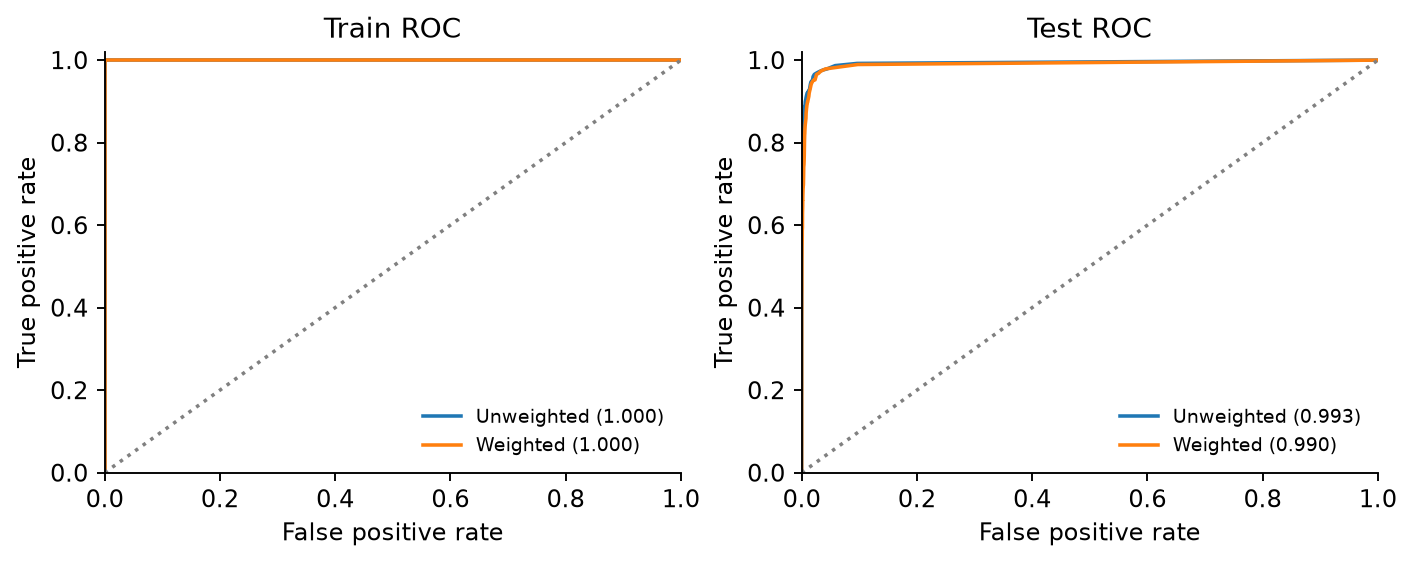

,OOB error,Test error
Unweighted,0.0059,0.0074
Weighted,0.0079,0.0110


In [6]:
def evaluate(models, datasets):
    results = []
    fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.2), layout='constrained')
    for ax, (split, (features, labels)) in zip(axes, datasets.items()):
        for name, model in models.items():
            probabilities = model.predict_proba(features)[:, 1]
            predictions = probabilities >= 0.5
            tn, fp, fn, tp = confusion_matrix(labels, predictions, labels=[0, 1]).ravel()
            auc = roc_auc_score(labels, probabilities)
            fpr, tpr, _ = roc_curve(labels, probabilities)
            ax.plot(fpr, tpr, label=f'{name} ({auc:.3f})')
            results.append([name, split, tn, fp, fn, tp,
                            (fp + fn) / len(labels), auc, 10 * fp + 500 * fn])
        ax.plot([0, 1], [0, 1], ':', color='gray')
        ax.set(title=f'{split} ROC', xlabel='False positive rate',
               ylabel='True positive rate', xlim=(0, 1), ylim=(0, 1.02))
        ax.legend(loc='lower right', fontsize=8, frameon=False)

    columns = ['Model', 'Split', 'TN', 'FP', 'FN', 'TP', 'Error', 'AUC', 'APS cost']
    table = pd.DataFrame(results, columns=columns).set_index(['Model', 'Split'])
    display(table.round({'Error': 4, 'AUC': 4}))
    plt.show()
    return table

forests = {}
for name, weights in [('Unweighted', None), ('Weighted', 'balanced_subsample')]:
    forest = RandomForestClassifier(n_estimators=120, oob_score=True,
                                    class_weight=weights, random_state=seed, n_jobs=8)
    forests[name] = forest.fit(X_train, y_train)

rf_data = {'Train': (X_train, y_train), 'Test': (X_test, y_test)}
rf_results = evaluate(forests, rf_data)
oob = pd.Series({name: 1 - model.oob_score_ for name, model in forests.items()})
rf_test = rf_results.xs('Test', level='Split')
display(pd.DataFrame({'OOB error': oob, 'Test error': rf_test['Error']}).round(4))

The unweighted forest had 105 missed failures and 14 false alarms on the test set. Weighting gave 159 misses and 17 false alarms. Test AUC was 0.993 before weighting and 0.990 after. OOB error was 0.59% vs. 0.74% test error without weights and 0.79% vs. 1.10% with weights.

### 1(e–f). XGBoost with and without SMOTE

I used XGBoost's binary logistic objective and tuned the L1 penalty `reg_alpha`. In XGBoost's tree booster, this penalty acts on the leaf weights. Each split still uses one feature, so the booster does not fit a separate logistic regression at each node. I used the same stratified five folds for both models and picked the alpha with the highest mean validation ROC AUC.

For SMOTE I scaled the features using the training fold, then used five nearest neighbors to create positives inside that fold. I left the validation and test class counts unchanged. For the final fits I used all 60,000 training rows.

In [7]:
def fit_xgb(features, labels, alpha):
    model = XGBClassifier(objective='binary:logistic', reg_alpha=alpha,
                          n_estimators=85, max_depth=4, learning_rate=0.15,
                          colsample_bytree=0.85, max_bin=128, tree_method='hist',
                          random_state=seed, n_jobs=8)
    return model.fit(features, labels)

alphas = [0.1, 1.0, 10.0]
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
cv_scores = []
for fit_rows, valid_rows in folds.split(raw_train, y_train):
    fit_x = fill_medians(raw_train.iloc[fit_rows])
    valid_x = fill_medians(raw_train.iloc[valid_rows])
    fit_y, valid_y = y_train[fit_rows], y_train[valid_rows]
    scaler = StandardScaler().fit(fit_x)
    smote = SMOTE(random_state=seed, k_neighbors=5)
    smote_x, smote_y = smote.fit_resample(scaler.transform(fit_x), fit_y)
    cases = [('No SMOTE', fit_x, fit_y, valid_x),
             ('SMOTE', smote_x, smote_y, scaler.transform(valid_x))]
    for name, fit_features, fit_labels, valid_features in cases:
        for alpha in alphas:
            model = fit_xgb(fit_features, fit_labels, alpha)
            scores = model.predict_proba(valid_features)[:, 1]
            error = np.mean((scores >= 0.5) != valid_y)
            cv_scores.append([name, alpha, roc_auc_score(valid_y, scores), error])

cv_results = pd.DataFrame(cv_scores, columns=['Model', 'Alpha', 'CV AUC', 'CV error'])
cv_means = cv_results.groupby(['Model', 'Alpha']).mean()
display(cv_means.round(4))
chosen = cv_means.reset_index().sort_values('CV AUC', ascending=False)
chosen = chosen.drop_duplicates('Model').set_index('Model')

CV AUC  CV error
Model    Alpha                  
No SMOTE 0.1    0.9882    0.0067
         1.0    0.9885    0.0067
         10.0   0.9895    0.0080
SMOTE    0.1    0.9861    0.0175
         1.0    0.9858    0.0171
         10.0   0.9859    0.0193

Full SMOTE counts (negative, positive): [59000 59000]


,,TN,FP,FN,TP,Error,AUC,APS cost
Model,Split,,,,,,,
No SMOTE,Train,58942,58,188,812,0.0041,0.9961,94580
SMOTE,Train,58405,595,57,943,0.0109,0.9975,34450
No SMOTE,Test,15597,28,105,270,0.0083,0.9953,52780
SMOTE,Test,15352,273,38,337,0.0194,0.9923,21730


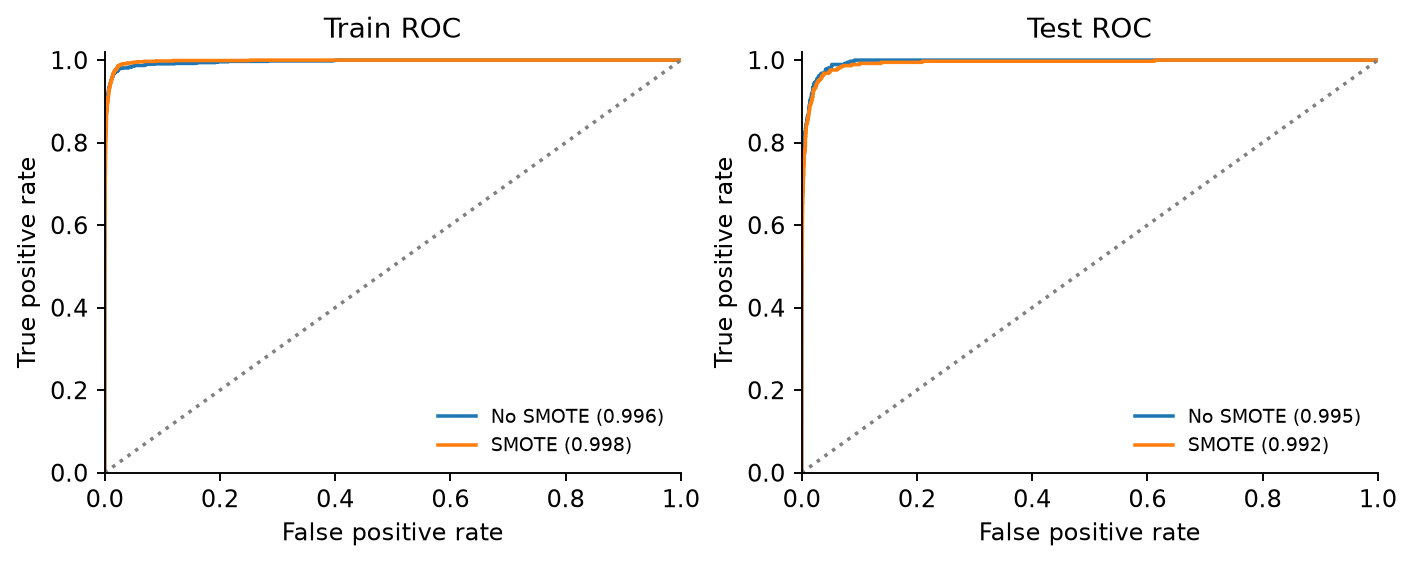

,Alpha,CV error,Test_error
Model,,,
No SMOTE,10.0,0.0080,0.0083
SMOTE,0.1,0.0175,0.0194


In [8]:
scaler = StandardScaler().fit(X_train)
smote = SMOTE(random_state=seed, k_neighbors=5)
final_x, final_y = smote.fit_resample(scaler.transform(X_train), y_train)
print('Full SMOTE counts (negative, positive):', np.bincount(final_y))

no_smote = fit_xgb(X_train, y_train, chosen.loc['No SMOTE', 'Alpha'])
with_smote = fit_xgb(final_x, final_y, chosen.loc['SMOTE', 'Alpha'])

xgb_models = {'No SMOTE': no_smote, 'SMOTE': make_pipeline(scaler, with_smote)}
xgb_results = evaluate(xgb_models, rf_data)
xgb_test = xgb_results.xs('Test', level='Split')
display(chosen[['Alpha', 'CV error']].assign(Test_error=xgb_test['Error']).round(4))

SMOTE changed the test misses from 105 to 38 and false alarms from 28 to 273. AUC went from 0.995 to 0.992, and APS cost went from 52,780 to 21,730. Test error was 0.83% without SMOTE and 1.94% with it. The corresponding five-fold errors were 0.80% and 1.75%.

The CV errors come from the same folds used to choose alpha. The official test set gives a separate check. APS cost uses $10$ per false positive and $500$ per false negative, as specified by UCI.

**References:** [Imputation](https://scikit-learn.org/stable/modules/impute.html) · [Random forest weights](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) · [XGBoost parameters](https://xgboost.readthedocs.io/en/stable/parameter.html) · [Resampling in CV](https://imbalanced-learn.org/stable/common_pitfalls.html)

## 2. ISLR 6.6.3

(a) **iv.** Training RSS decreases or stays flat. A larger $s$ allows more fits, and the RSS levels off once least squares is allowed.

(b) **ii.** Test RSS usually falls at first, then rises if the model starts to overfit.

(c) **iii.** Variance generally rises because a looser constraint lets the fit change more across training samples.

(d) **iv.** Squared bias generally falls because a more flexible model can get closer to the true relationship.

(e) **v.** Irreducible error stays constant because it comes from noise in the response.

## 3. ISLR 6.6.5

Let $a=x_{11}=x_{12}$ and $b=y_1$. The second row has predictors $-a,-a$ and response $-b$. With $t=\beta_1+\beta_2$, the RSS is $2(b-at)^2$.

(a) Ridge minimizes $2(b-at)^2+\lambda(\beta_1^2+\beta_2^2)$.

(b) At fixed $t$, the penalty is smallest at $\beta_1=\beta_2=t/2$, since $\beta_1^2+\beta_2^2=[t^2+(\beta_1-\beta_2)^2]/2$. Therefore ridge gives equal coefficients when $\lambda>0$.

(c) Lasso minimizes $2(b-at)^2+\lambda(|\beta_1|+|\beta_2|)$.

(d) Let $t^*$ minimize $2(b-at)^2+\lambda|t|$. Any split of $t^*$ with both coefficients of the same sign (allowing zero) gives the same RSS and penalty. For example, $(t^*,0)$ and $(t^*/2,t^*/2)$ both work. If $t^*=0$ and $\lambda>0$, the only solution is $(0,0)$.

## 4. ISLR 8.4.5

**Majority vote: Red.** Six of the ten probabilities exceed 0.5.

**Average probability: Green.** The mean probability of Red is $4.50/10=0.45$.

## 5. ISLR 9.7.3

(a) The left panel labels the seven observations.

(b–c) The maximal-margin line is $x_2=x_1-0.5$. With $(\beta_0,\beta_1,\beta_2)=(1/(2\sqrt{2}),-1/\sqrt{2},1/\sqrt{2})$, predict Red if $\beta_0+\beta_1x_1+\beta_2x_2>0$, and Blue otherwise.

(d–e) The dashed lines are $x_2=x_1$ and $x_2=x_1-1$. They touch the parallel edges of the class hulls. The separator is halfway between them, at distance $1/(2\sqrt{2})$ from either edge. Observations 2, 3, 5, and 6 are the support vectors.

(f) Observation 7 is beyond the blue margin. A small move keeps it outside the margin and leaves the separator in place.

(g) The dotted line $x_2=x_1-0.25$ also separates the classes, with less room on the red side.

(h) A blue point at $(3,3)$ lies on the segment between red points 2 and 3, so no line can strictly separate the classes.

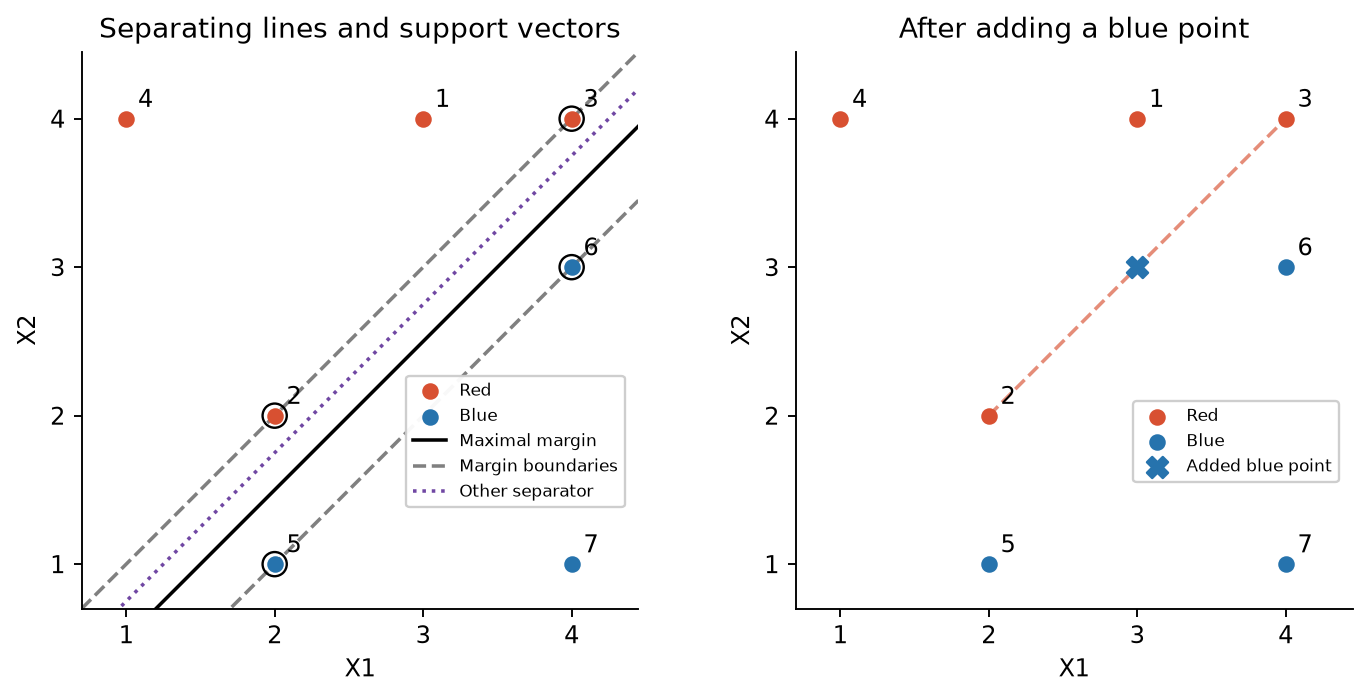

In [9]:
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
x = np.linspace(0.7, 4.45, 200)
fig, axes = plt.subplots(1, 2, figsize=(8.4, 4), layout='constrained')
for ax in axes:
    ax.scatter(*points[:4].T, color='#d85031', label='Red', zorder=3)
    ax.scatter(*points[4:].T, color='#2673ad', label='Blue', zorder=3)
    for i, (x1, x2) in enumerate(points, start=1):
        ax.annotate(str(i), (x1, x2), xytext=(5, 5), textcoords='offset points')
    ax.set(xlabel='X1', ylabel='X2', xlim=(0.7, 4.45), ylim=(0.7, 4.45),
           xticks=[1, 2, 3, 4], yticks=[1, 2, 3, 4], aspect='equal')

left, right = axes
left.plot(x, x - 0.5, color='black', label='Maximal margin')
left.plot(x, x, '--', color='gray', label='Margin boundaries')
left.plot(x, x - 1, '--', color='gray')
left.plot(x, x - 0.25, ':', color='#7047a3', label='Other separator')
support = points[[1, 2, 4, 5]]
left.scatter(*support.T, facecolors='none', edgecolors='black', s=105, zorder=4)
left.set_title('Separating lines and support vectors')
left.legend(loc='center right', bbox_to_anchor=(0.99, 0.30), fontsize=7, framealpha=0.95)
right.plot([2, 4], [2, 4], '--', color='#d85031', alpha=0.65)
right.scatter(3, 3, color='#2673ad', marker='X', s=80, label='Added blue point', zorder=4)
right.set_title('After adding a blue point')
right.legend(loc='center right', bbox_to_anchor=(0.99, 0.30), fontsize=7, framealpha=0.95)
plt.show()